In [11]:
import sys
import os
from IPython.display import clear_output, display
from importnb import Notebook
from pathlib import Path
import re
import torch.nn.functional as F
from torch.utils.data import DataLoader
from collections import defaultdict
target_path = r'C:\Users\alex1\OneDrive\Alex\OneDrive\Desktop\LocalizationModel\Functions'
if target_path not in sys.path:
    sys.path.insert(0, target_path)
with Notebook():
    from Functions1 import *
    print("Success!")
target_path1 = r'C:\Users\alex1\OneDrive\Alex\OneDrive\Desktop\LocalizationModel'
if target_path1 not in sys.path:
    sys.path.insert(0, target_path1)
with Notebook():
    from DataLoader import *
    print("Success!")

Success!
Success!


# Single Frame Spatial 2D Convolutional Block

In [12]:
class SpatialConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.C1 = nn.Conv2d(in_channels=in_channels,out_channels=6,kernel_size=3,stride=2,padding=1,bias=True)
        self.Norm1 = nn.GroupNorm(3,6,affine=True)
        self.C2 = nn.Conv2d(in_channels=6,out_channels=12,kernel_size=3,stride=2,padding=1,bias=True)
        self.Norm2 = nn.GroupNorm(4,12,affine=True)
        self.C3 = nn.Conv2d(in_channels=12,out_channels=24,kernel_size=3,stride=2,padding=1,bias=True)
        self.Norm3 = nn.GroupNorm(8,24,affine=True)
        self.BottleNeck = nn.Conv2d(24,24,kernel_size=3,stride=1,padding=1)
        self.Up3 = nn.Sequential(nn.Upsample(scale_factor=2,mode='bilinear',align_corners=False),nn.Conv2d(24,12,kernel_size=3,padding=1,bias=True))
        self.Up2 = nn.Sequential(nn.Upsample(scale_factor=2,mode='bilinear',align_corners=False),nn.Conv2d(12,6,kernel_size=3,padding=1,bias=True))
        self.Up1 = nn.Sequential(nn.Upsample(scale_factor=2,mode='bilinear',align_corners=False),nn.Conv2d(6,out_channels,kernel_size=3,padding=1,bias=True))
    def forward(self, x):
        x1 = F.gelu(self.Norm1(self.C1(x)))     #6x128x128
        x2 = F.gelu(self.Norm2(self.C2(x1)))    #12x64x64
        x3 = F.gelu(self.BottleNeck(self.Norm3(self.C3(x2))))    #24x32x32
        x4 = F.gelu(self.Up3(x3)+x2)            #12x64x64
        x5 = F.gelu(self.Up2(x4)+x1)            #6x128x128
        x6 = F.sigmoid(self.Up1(x5))            #1x256x256
        return x6

# Spatial Encoder

In [13]:
class SpatialEncoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.Spatial = SpatialConvBlock(in_channels, out_channels)
    def forward(self, x):
        b,t,c,h,w = x.shape
        space_masks = []
        for i in range(t):
            space_masks.append(self.Spatial(x[:,i,...]))
        return torch.stack(space_masks,dim=1)

# Temporal Block

In [15]:
class TemporalConvBlock(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.C1 = nn.Conv3d(in_channels=in_channels,out_channels=6,kernel_size=(3,3,3),stride=(1,2,2),padding=(1,1,1),bias=True)
        self.Norm1 = nn.GroupNorm(3,6,affine=True)
        self.C2 = nn.Conv3d(in_channels=6,out_channels=12,kernel_size=(3,3,3),stride=(1,2,2),padding=(1,1,1),bias=True)
        self.Norm2 = nn.GroupNorm(4,12,affine=True)
    def forward(self, x):
        x1 = F.gelu(self.Norm1(self.C1(x)))     #6x8x128x128
        x2 = F.gelu(self.Norm2(self.C2(x1)))    #12x8x64x64
        return x2

# Temporal Encoder

In [16]:
class TemporalEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.RGB = TemporalConvBlock(3)
        self.Variance = TemporalConvBlock(1)
        self.Flow = TemporalConvBlock(2)
        self.Fusion = nn.Sequential(
            nn.Conv3d(36,24,kernel_size=3,padding=1,bias=True),
            nn.GroupNorm(8,24),
            nn.GELU(),
            nn.Conv3d(24,12,kernel_size=3,padding=1,bias=True),
            nn.GroupNorm(4,12),
            nn.GELU()
        )
        self.Up = nn.Sequential(
            nn.Upsample(scale_factor=(1, 2, 2),mode='trilinear',align_corners=False),
            nn.Conv3d(12,6,kernel_size=3,padding=1,bias=True),
            nn.GroupNorm(2,6),
            nn.GELU(),
            nn.Upsample(scale_factor=(1, 2, 2),mode='trilinear',align_corners=False),
            nn.Conv3d(6,1,kernel_size=3,padding=1,bias=True)
        )
    def forward(self,x):
        x = x.permute(0,2,1,3,4).contiguous()
        rgb = self.RGB(x[:,:3])
        variance = self.Variance(x[:,3:4])
        flow = self.Flow(x[:,4:6])
        fused = torch.cat([rgb,variance,flow],dim=1)
        bottleneck = self.Fusion(fused)
        output = self.Up(bottleneck).permute(0,2,1,3,4).contiguous()
        return F.sigmoid(output)

# Spatio-Temporal Fusion

In [21]:
class STFusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.Spatial = SpatialEncoder(3,1)
        self.Temporal = TemporalEncoder()
        self.Fusion = SpatialEncoder(2,1)
    def forward(self,x):
        space = self.Spatial(x[:,:,:3,...])
        time = self.Temporal(x)
        output = self.Fusion(torch.cat([space,time],dim=2))
        return output,space,time

# Loss Function

In [47]:
def segmentation_loss(logits,targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).sum(dim=(2,3,4))
    denominator = (probabilities.sum(dim=(2,3,4)) +targets.sum(dim=(2,3,4)))
    dice = (2.0 * intersection + 1e-12) / (denominator + 1e-12)
    dice_loss = 1.0 - dice.mean()
    total = bce +  dice_loss
    return total

In [48]:
def loss_function(space,time,final,targets):
    l_space = segmentation_loss(space,targets)
    l_time = segmentation_loss(time,targets)
    l_final = segmentation_loss(final,targets)
    return 0.25*l_space + 0.25*l_time + 0.5*l_final

# Training Function

In [ ]:
def train_model(model,train_loader,val_loader=None,epochs=50,learning_rate=1e-4, weight_decay=1e-4, use_amp=True, threshold=0.5,
    grad_clip=1.0, steps_per_epoch=None, val_steps=None, patience=10,min_delta=1e-4, save_path="best_video_localizer.pth",
    latest_path="latest_video_localizer.pth", resume_path=None,display_batch=None, N_dis=5, 
    display_video_index=0,display_threshold=0.5, display_binary=False
):
    if N_dis < 1:
        raise ValueError("N_dis must be >= 1.")

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-7
    )

    amp_enabled = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

    history = defaultdict(list)
    best_loss = float("inf")
    epochs_without_improvement = 0
    start_epoch = 1

    # Resume previous training.
    if resume_path is not None:
        if not os.path.isfile(resume_path):
            raise FileNotFoundError(f"Checkpoint not found: {resume_path}")

        try:
            checkpoint = torch.load(
                resume_path, map_location=device, weights_only=False
            )
        except TypeError:
            checkpoint = torch.load(resume_path, map_location=device)

        model.load_state_dict(checkpoint["model_state_dict"])

        if "optimizer_state_dict" in checkpoint:
            optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        if "scheduler_state_dict" in checkpoint:
            scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

        if "scaler_state_dict" in checkpoint and scaler.is_enabled():
            scaler.load_state_dict(checkpoint["scaler_state_dict"])

        best_loss = checkpoint.get("best_loss", float("inf"))
        epochs_without_improvement = checkpoint.get(
            "epochs_without_improvement", 0
        )

        history.update(checkpoint.get("history", {}))
        start_epoch = checkpoint.get("epoch", 0) + 1

        print(f"\nResuming training from: {resume_path}")
        print(f"Last saved epoch: {start_epoch - 1}")
        print(f"Best loss: {best_loss:.6f}")
        print(f"Learning rate: {optimizer.param_groups[0]['lr']:.2e}")

        if "scaler_state_dict" not in checkpoint:
            print("No saved AMP scaler state. Using a fresh scaler.")

    if start_epoch > epochs:
        print(f"Training already reached epoch {start_epoch - 1}.")
        return model, dict(history)

    def make_checkpoint(epoch):
        return {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_loss": best_loss,
            "epochs_without_improvement": epochs_without_improvement,
            "history": dict(history)
        }

    def save_checkpoint(path, epoch):
        if path is None:
            return
        directory = os.path.dirname(path)
        if directory:
            os.makedirs(directory, exist_ok=True)
        torch.save(make_checkpoint(epoch), path)

    for epoch in range(start_epoch, epochs + 1):

        train_metrics = run_epoch(
            model=model,
            data_source=train_loader,
            device=device,
            optimizer=optimizer,
            scaler=scaler,
            use_amp=use_amp,
            pos_weight=pos_weight,
            bce_weight=bce_weight,
            dice_weight=dice_weight,
            threshold=threshold,
            grad_clip=grad_clip,
            steps=steps_per_epoch
        )

        if val_loader is not None:
            val_metrics = run_epoch(
                model=model,
                data_source=val_loader,
                device=device,
                use_amp=use_amp,
                pos_weight=pos_weight,
                bce_weight=bce_weight,
                dice_weight=dice_weight,
                threshold=threshold,
                steps=val_steps
            )
            monitored_loss = val_metrics["loss"]
        else:
            val_metrics = None
            monitored_loss = train_metrics["loss"]

        scheduler.step(monitored_loss)

        for key, value in train_metrics.items():
            history["train_" + key].append(value)

        if val_metrics is not None:
            for key, value in val_metrics.items():
                history["val_" + key].append(value)

        current_lr = optimizer.param_groups[0]["lr"]
        history["learning_rate"].append(current_lr)

        print(
            f"Epoch {epoch:03d}/{epochs} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Train F1: {train_metrics['f1']:.4f} | "
            f"Train IoU: {train_metrics['iou']:.4f} | "
            f"Train Empty-FP: {train_metrics['empty_frame_fp_rate']:.4f}"
        )

        if val_metrics is not None:
            print(
                f"                 "
                f"Val Loss: {val_metrics['loss']:.4f} | "
                f"Val F1: {val_metrics['f1']:.4f} | "
                f"Val IoU: {val_metrics['iou']:.4f} | "
                f"Val Empty-FP: {val_metrics['empty_frame_fp_rate']:.4f}"
            )

        print(f"                 Learning rate: {current_lr:.2e}")

        improved = monitored_loss < best_loss - min_delta

        if improved:
            best_loss = monitored_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Save best checkpoint when performance improves.
        if improved:
            save_checkpoint(save_path, epoch)
            if save_path is not None:
                print(f"                 Saved best model: {save_path}")

        # Save latest checkpoint after EVERY completed epoch.
        save_checkpoint(latest_path, epoch)
        if latest_path is not None:
            print(f"                 Saved latest checkpoint: {latest_path}")

        # Generate a new visualization batch every N_dis epochs.
        if display_batch is not None and epoch % N_dis == 0:

            print(f"\nGenerating new visualization video for epoch {epoch}...")

            current_display_batch = (
                display_batch()
                if callable(display_batch)
                else display_batch
            )

            display_video_predictions(
                model=model,
                batch=current_display_batch,
                device=device,
                video_index=display_video_index,
                threshold=display_threshold,
                show_binary=display_binary
            )

        if val_loader is not None and epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}.")
            break

    return model, dict(history)


In [ ]:
display_batch_fn = lambda: generate_video_batch(batch_size=1,n_frames=N_FRAMES,resize_shape=RESIZE_SHAPE,tf_thresh=0.35,device="cpu",channels_first=False)
BATCH_SIZE = 2
train_batch_fn = lambda: generate_video_batch(batch_size=BATCH_SIZE,n_frames=N_FRAMES,resize_shape=RESIZE_SHAPE,tf_thresh=0.5,device="cpu",
                                              channels_first=False)
model = VideoArtifactLocalizer()
model, history = train_model(model=model,train_loader=train_batch_fn,val_loader=None,epochs=50,steps_per_epoch=10,device=device,learning_rate=2e-3,
                             patience=10,save_path="Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth",
                             latest_path="Checkpoints/VideoArtifactLocalizer_best_bias_affine.pth",
                             display_batch=display_batch_fn,N_dis=5,display_binary=False)

Data: torch.Size([2, 8, 6, 256, 256]) 	Masks: torch.Size([2, 8, 1, 256, 256])


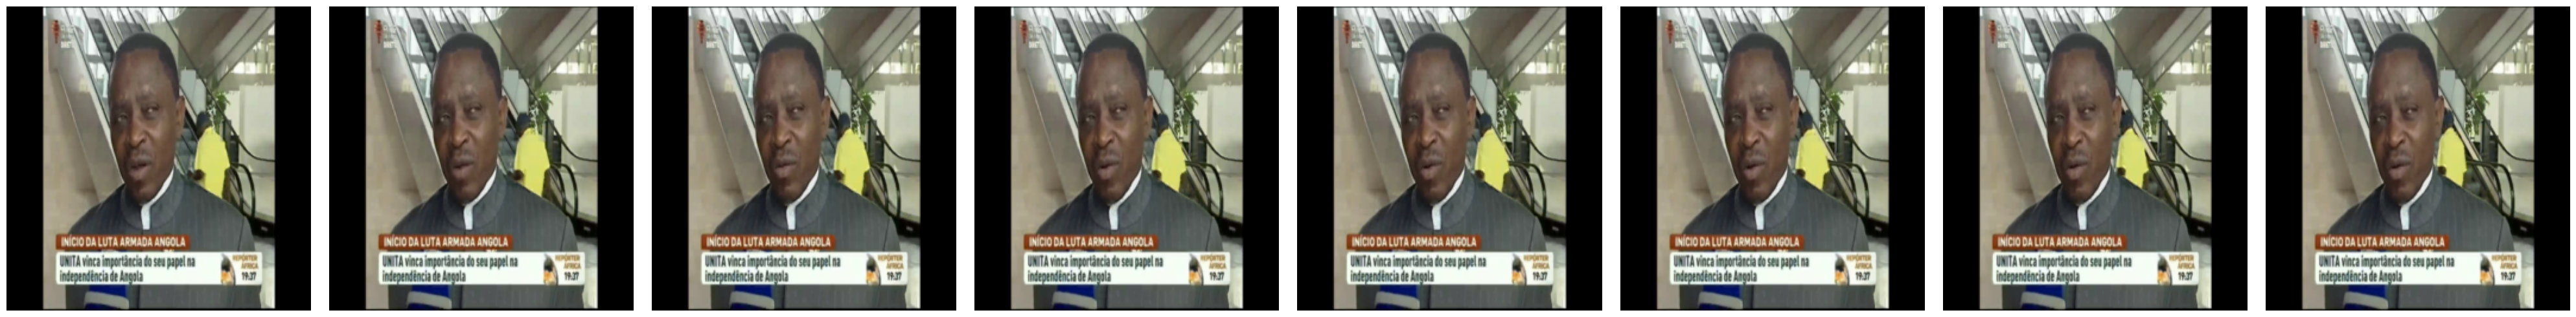

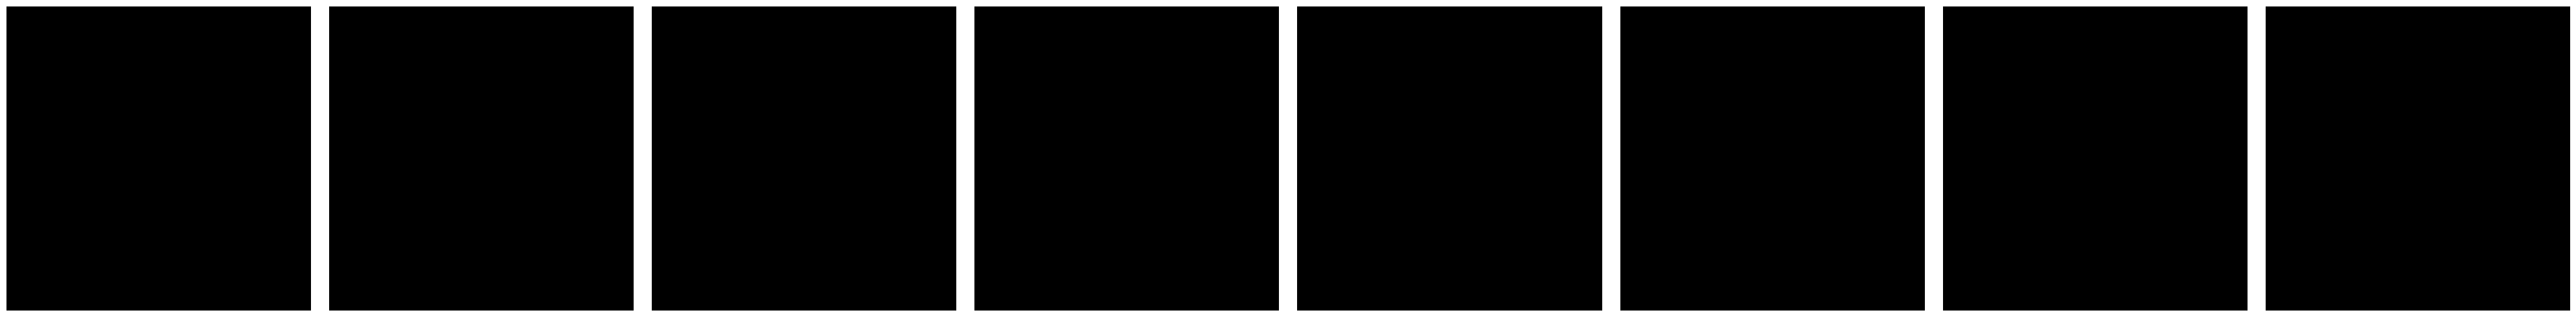

Output: torch.Size([2, 8, 1, 256, 256])


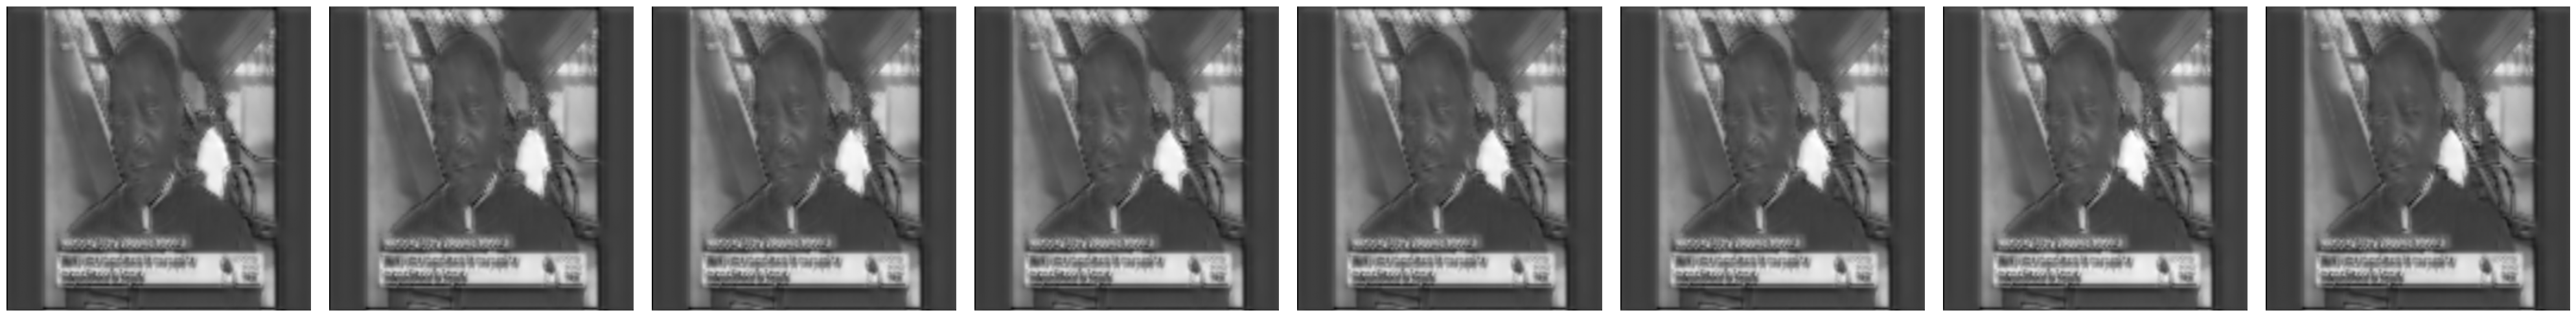

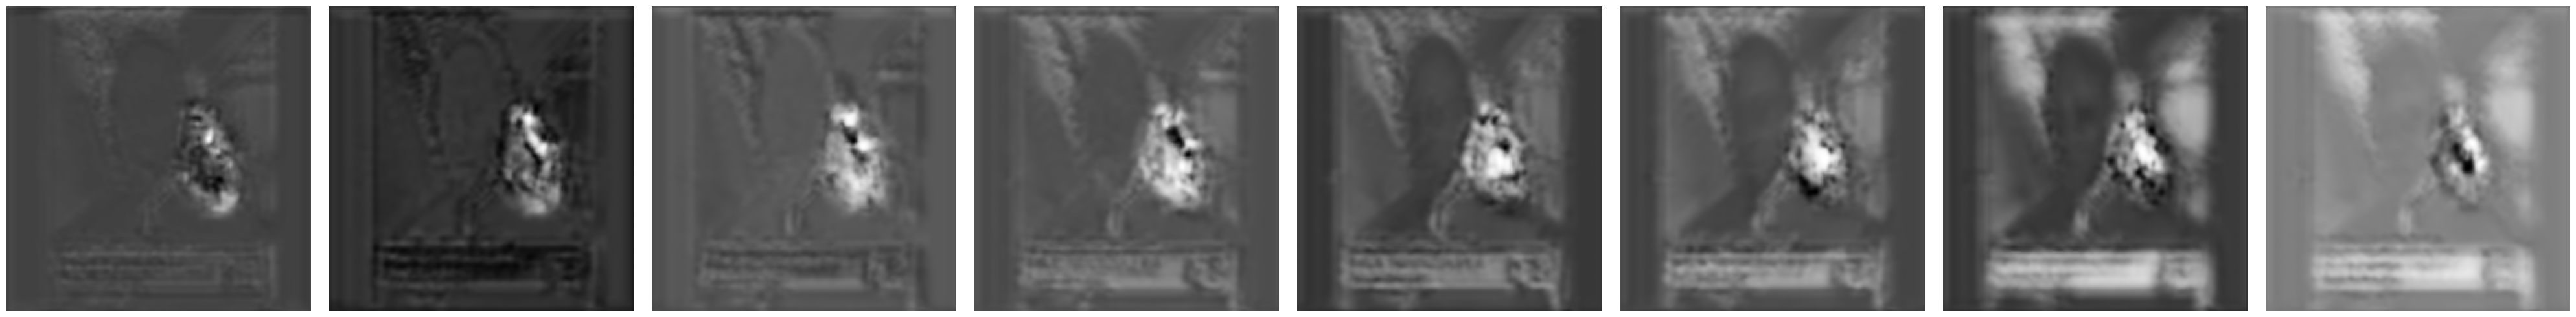

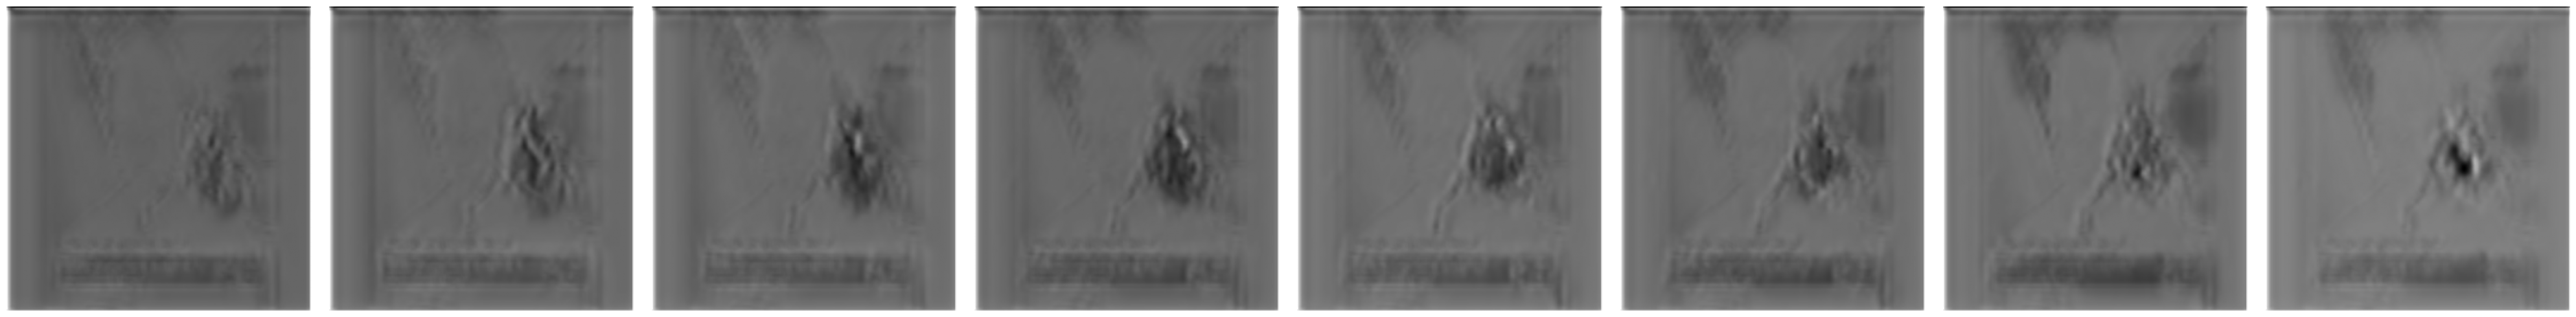

tensor(1.9613, device='cuda:0', grad_fn=<AddBackward0>)

In [56]:
X,M = generate_video_batch(batch_size=2,n_frames=8,resize_shape=(256,256),tf_thresh=0.5,device=device,channels_first=False)

print("Data:",X.shape,"\tMasks:",M.shape)
     
fx = [Frame2Numpy(X[0][i][:3,...])*255 for i in range(X.shape[1])]
fm = [Frame2Numpy(M[0][i][0,...])*255 for i in range(M.shape[1])]
display_images_plot(fx,cols=X.shape[1])
display_images_plot(fm,cols=M.shape[1])

model = STFusion().to(device)

res,space,time = model(X)

print("Output:",res.shape)

fres = [Frame2Numpy(space[0,i,0,...])*255 for i in range(space.shape[1])]
display_images_plot(fres,cols=space.shape[1])
fres = [Frame2Numpy(time[0,i,0,...])*255 for i in range(time.shape[1])]
display_images_plot(fres,cols=time.shape[1])
fres = [Frame2Numpy(res[0,i,0,...])*255 for i in range(res.shape[1])]
display_images_plot(fres,cols=res.shape[1])

loss = loss_function(space,time,res,M)
loss

# Generate Batches

# Evaluation Metrics

# Run Single Epoch

# Display Function

# Training Function

# Training